# Up-Sell Model

**Goal:** For customers already buying in a product group at below-median prices, recommend premium-tier items popular among customers in the same RFM cluster.

**Approach:**
1. Define price tiers per product group: items with avg price ≥ PG median → **premium**, below → **standard**
2. Identify up-sell targets: customers whose avg purchase price in a PG is below the PG median
3. Build cluster-conditional popularity: for each (Cluster, PG), rank premium items by how many cluster customers bought them
4. Generate recommendations: top-K premium items the customer hasn't bought yet
5. Validate with label window: check if targeted customers moved toward higher prices

**Train period:** 2018-01-01 → 2019-06-30  
**Label period:** 2019-07-01 → 2020-06-30

In [1]:
import pandas as pd
import numpy as np
import json
from pathlib import Path
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

TRAIN_END  = pd.Timestamp('2019-07-01')
LABEL_END  = pd.Timestamp('2020-07-01')
TOP_K      = 5
DATA_DIR   = Path('../data/processed')

OUT_DATA  = Path('../data/processed/upsell')
OUT_MODEL = Path('../models/upsell')
OUT_DATA.mkdir(parents=True, exist_ok=True)
OUT_MODEL.mkdir(parents=True, exist_ok=True)

print(f'Output data  → {OUT_DATA}')
print(f'Output model → {OUT_MODEL}')

Output data  → ../data/processed/upsell
Output model → ../models/upsell


## 1. Load Data

In [2]:
df = pd.read_csv(DATA_DIR / 'data_clean_final.csv')
df['Invoice Date'] = pd.to_datetime(df['Invoice Date'])
df = df[df['CustomerID'] != -99]
df = df[df['Product group'] != 'Unknown']
df = df[df['Invoiced price'] > 0]

rfm = pd.read_csv(DATA_DIR / 'rfm_segments.csv')
rfm = rfm[rfm['CustomerID'] != -99][['CustomerID', 'Cluster_name']]

train = df[df['Invoice Date'] < TRAIN_END].copy()
label = df[(df['Invoice Date'] >= TRAIN_END) & (df['Invoice Date'] < LABEL_END)].copy()

print(f"Train rows : {len(train):,}")
print(f"Label rows : {len(label):,}")
print(f"Train customers : {train['CustomerID'].nunique():,}")
print(f"Product groups  : {train['Product group'].nunique()}")

Train rows : 560,621
Label rows : 324,411
Train customers : 9,017
Product groups  : 30


## 2. Price Tier Analysis

For each item within a product group, compute its average price across all train transactions. Then compute the median of those item averages per PG. Items at or above the median are **premium**; below are **standard**.

In [3]:
# Average price per (PG, Item) in train
item_prices = (
    train.groupby(['Product group', 'Item Code'])['Invoiced price']
    .mean()
    .reset_index()
    .rename(columns={'Invoiced price': 'item_avg_price'})
)

# PG median of item avg prices
pg_medians = (
    item_prices.groupby('Product group')['item_avg_price']
    .median()
    .reset_index()
    .rename(columns={'item_avg_price': 'pg_median_price'})
)

# Classify each item
item_tiers = item_prices.merge(pg_medians, on='Product group')
item_tiers['tier'] = np.where(
    item_tiers['item_avg_price'] >= item_tiers['pg_median_price'],
    'premium', 'standard'
)

print('Item tier distribution:')
print(item_tiers['tier'].value_counts())
print(f"\nTotal items: {len(item_tiers):,}")
print(f"PGs covered: {item_tiers['Product group'].nunique()}")

Item tier distribution:
tier
premium     19382
standard    19352
Name: count, dtype: int64

Total items: 38,734
PGs covered: 30


In [4]:
# Median price by PG — overview
pg_medians_view = pg_medians.merge(
    item_tiers.groupby('Product group').agg(
        n_items=('Item Code', 'count'),
        n_premium=('tier', lambda x: (x == 'premium').sum())
    ).reset_index(),
    on='Product group'
).sort_values('pg_median_price', ascending=False)

print(pg_medians_view.to_string(index=False))

Product group  pg_median_price  n_items  n_premium
        PC030      4624.500000      122         61
        PC007      3425.000000      178         89
        PC003      1352.200000      113         57
        PC019       732.000000      761        381
        PC012       541.154762      564        282
        PC029       264.290000       47         24
        PC028       121.593633      115         58
        PC016        81.483630      985        493
        SF001        48.632308        1          1
        PC014        43.200000     1033        517
        SF002        40.990625      967        484
        PC001        39.700000     2480       1240
        PC023        21.100000      621        311
        PC013        10.060000     4755       2378
        PC008         6.805650     1228        614
        PC004         6.057333      306        153
        PC017         5.449850       29         15
        PC015         5.039700      452        226
        PC002         3.420000 

## 3. Identify Up-Sell Targets

A customer is an up-sell target in a product group if their average price paid in that PG during the train period is **below the PG median**. This means they are a known buyer in the PG, but buying lower-tier items.

In [5]:
# Customer avg price per PG in train
cust_pg_price = (
    train.groupby(['CustomerID', 'Product group'])['Invoiced price']
    .mean()
    .reset_index()
    .rename(columns={'Invoiced price': 'cust_avg_price'})
)

# Merge PG median
cust_pg_price = cust_pg_price.merge(pg_medians, on='Product group')

# Up-sell targets: avg price < PG median
targets = cust_pg_price[cust_pg_price['cust_avg_price'] < cust_pg_price['pg_median_price']].copy()
targets = targets.merge(rfm, on='CustomerID', how='left')

print(f"Customer × PG combos in train   : {len(cust_pg_price):,}")
print(f"Up-sell targets (below median)   : {len(targets):,} ({len(targets)/len(cust_pg_price):.1%})")
print(f"Unique customers with up-sell    : {targets['CustomerID'].nunique():,}")
print()
print('Targets by cluster:')
print(targets['Cluster_name'].value_counts())

Customer × PG combos in train   : 13,402
Up-sell targets (below median)   : 6,458 (48.2%)
Unique customers with up-sell    : 4,993

Targets by cluster:
Cluster_name
Mid-Tier At Risk       2038
Whales / Champions     1984
Active Small Buyers    1665
Hibernating             771
Name: count, dtype: int64


## 4. Premium Item Popularity by Cluster

For each (Cluster, PG, Item), count how many unique customers in that cluster bought that item during train. **Confidence** = n_buyers / n_cluster_customers_in_PG.

### Filtering: minimum 2 buyers per (Cluster, PG, Item)

Items with only 1 buyer in a cluster–PG group get 100% confidence from a single purchase,
which is noise rather than signal. The `n_buyers >= 2` filter removes these degenerate cases.

**Known edge case — SF001 (Fittings):** this PG has only one item (`363999`), so any
cluster with 2+ buyers of that item still hits 100% confidence. Technically valid,
but the recommendation is trivially "buy the only item in this group."

In [6]:
# Premium items only
premium_items = item_tiers[item_tiers['tier'] == 'premium'][['Product group', 'Item Code', 'item_avg_price']]

# Tag train with cluster
train_clustered = train.merge(rfm, on='CustomerID', how='left').dropna(subset=['Cluster_name'])

# Denominator: customers per (cluster, PG)
cluster_pg_customers = (
    train_clustered.groupby(['Cluster_name', 'Product group'])['CustomerID']
    .nunique()
    .reset_index()
    .rename(columns={'CustomerID': 'n_cluster_pg_customers'})
)

# Premium item buyers per (cluster, PG, item)
premium_train = train_clustered.merge(premium_items, on=['Product group', 'Item Code'])

item_popularity = (
    premium_train.groupby(['Cluster_name', 'Product group', 'Item Code'])['CustomerID']
    .nunique()
    .reset_index()
    .rename(columns={'CustomerID': 'n_buyers'})
)

item_popularity = (
    item_popularity
    .merge(cluster_pg_customers, on=['Cluster_name', 'Product group'])
    .merge(premium_items, on=['Product group', 'Item Code'])
)

item_popularity['confidence'] = item_popularity['n_buyers'] / item_popularity['n_cluster_pg_customers']

# Remove single-buyer noise: 1/1 = 100% confidence from one purchase is meaningless
item_popularity = item_popularity[item_popularity['n_buyers'] >= 2]

print(f"Item popularity records: {len(item_popularity):,}")
print()
print('Top 15 by confidence:')
print(
    item_popularity
    .sort_values('confidence', ascending=False)
    [['Cluster_name', 'Product group', 'Item Code', 'n_buyers', 'n_cluster_pg_customers', 'confidence', 'item_avg_price']]
    .head(15)
    .to_string(index=False)
)

Item popularity records: 4,142

Top 15 by confidence:
       Cluster_name Product group       Item Code  n_buyers  n_cluster_pg_customers  confidence  item_avg_price
 Whales / Champions         SF001          363999         2                       2    1.000000       48.632308
Active Small Buyers         PC018   BAL-232010-16         4                      12    0.333333        5.292071
   Mid-Tier At Risk         SF002          056325        12                      46    0.260870      601.720652
   Mid-Tier At Risk         PC023          401300         8                      33    0.242424      466.361312
        Hibernating         PC011      JUN-069069         2                       9    0.222222        1.491957
Active Small Buyers         PC023          401300        12                      71    0.169014      466.361312
        Hibernating         PC015        21531254         2                      13    0.153846       11.138381
 Whales / Champions         PC007         TOOLING 

In [7]:
# ── 4b. All-Item Popularity by Cluster — for cross-sell Layer 2 item drill-down
# Same logic as item_popularity above but without the premium-only filter.
# When /cross-sell recommends a new PG to a customer, this table provides the
# specific items to suggest within that PG (most popular among similar cluster customers).

item_popularity_all = (
    train_clustered.groupby(['Cluster_name', 'Product group', 'Item Code'])['CustomerID']
    .nunique()
    .reset_index()
    .rename(columns={'CustomerID': 'n_buyers'})
)

item_popularity_all = (
    item_popularity_all
    .merge(cluster_pg_customers, on=['Cluster_name', 'Product group'])
    .merge(item_prices, on=['Product group', 'Item Code'])
)

item_popularity_all['confidence'] = (
    item_popularity_all['n_buyers'] / item_popularity_all['n_cluster_pg_customers']
)

# Same n_buyers >= 2 filter — removes single-purchase noise
item_popularity_all = item_popularity_all[item_popularity_all['n_buyers'] >= 2]

item_popularity_all.to_csv(OUT_DATA / 'upsell_item_popularity_all.csv', index=False)

print(f"All-item popularity records  : {len(item_popularity_all):,}")
print(f"Premium-only records         : {len(item_popularity):,}")
print(f"Saved → {OUT_DATA}/upsell_item_popularity_all.csv")
print(f"\nTop 10 by confidence (all items):")
print(
    item_popularity_all
    .sort_values('confidence', ascending=False)
    [['Cluster_name', 'Product group', 'Item Code', 'n_buyers', 'n_cluster_pg_customers', 'confidence']]
    .head(10)
    .to_string(index=False)
)

All-item popularity records  : 9,530
Premium-only records         : 4,142
Saved → ../data/processed/upsell/upsell_item_popularity_all.csv

Top 10 by confidence (all items):
       Cluster_name Product group     Item Code  n_buyers  n_cluster_pg_customers  confidence
 Whales / Champions         SF001        363999         2                       2    1.000000
   Mid-Tier At Risk         PC007         SANDH       155                     228    0.679825
Active Small Buyers         PC007        OTESC1       108                     159    0.679245
 Whales / Champions         PC007        OTESC1        52                      83    0.626506
   Mid-Tier At Risk         PC020      PFS00256         2                       4    0.500000
        Hibernating         PC007        OTESC1         5                      12    0.416667
 Whales / Champions         PC028        648884         5                      15    0.333333
Active Small Buyers         PC018 BAL-232010-16         4                  

## 5. Generate Recommendations

For each up-sell target (customer × PG), recommend the top-K premium items from their cluster that they have **not already purchased**.

In [8]:
# Items each customer already bought per PG in train
cust_bought = (
    train.groupby(['CustomerID', 'Product group'])['Item Code']
    .apply(set)
    .to_dict()
)

# Pre-index item_popularity for fast lookup
pop_index = (
    item_popularity
    .sort_values('confidence', ascending=False)
    .groupby(['Cluster_name', 'Product group'])
)

recommendations = []

for _, row in targets.iterrows():
    cust_id  = row['CustomerID']
    pg       = row['Product group']
    cluster  = row['Cluster_name']

    if pd.isna(cluster):
        continue

    key = (cluster, pg)
    if key not in pop_index.groups:
        continue

    candidates = pop_index.get_group(key)
    already_bought = cust_bought.get((cust_id, pg), set())

    recs = candidates[~candidates['Item Code'].isin(already_bought)].head(TOP_K)

    for rank, (_, rec) in enumerate(recs.iterrows(), 1):
        recommendations.append({
            'CustomerID'      : cust_id,
            'product_group'   : pg,
            'cluster'         : cluster,
            'item_code'       : rec['Item Code'],
            'rank'            : rank,
            'confidence'      : round(rec['confidence'], 4),
            'item_avg_price'  : round(rec['item_avg_price'], 4),
            'cust_avg_price'  : round(row['cust_avg_price'], 4),
            'pg_median_price' : round(row['pg_median_price'], 4),
        })

recs_df = pd.DataFrame(recommendations)

print(f"Total recommendations   : {len(recs_df):,}")
print(f"Customers covered       : {recs_df['CustomerID'].nunique():,}")
print(f"PGs covered             : {recs_df['product_group'].nunique()}")
print()
print('Recommendations per cluster:')
print(recs_df.groupby('cluster')['CustomerID'].nunique())

Total recommendations   : 27,744
Customers covered       : 4,843
PGs covered             : 26

Recommendations per cluster:
cluster
Active Small Buyers    1309
Hibernating             593
Mid-Tier At Risk       1808
Whales / Champions     1133
Name: CustomerID, dtype: int64


In [9]:
# Sample recommendations for a few customers
sample_customers = recs_df['CustomerID'].drop_duplicates().head(3).tolist()
for cid in sample_customers:
    sub = recs_df[recs_df['CustomerID'] == cid]
    cluster = sub['cluster'].iloc[0]
    print(f"\nCustomer {cid} (cluster: {cluster})")
    print(sub[['product_group', 'item_code', 'rank', 'confidence', 'cust_avg_price', 'pg_median_price', 'item_avg_price']].to_string(index=False))


Customer 13 (cluster: Mid-Tier At Risk)
product_group  item_code  rank  confidence  cust_avg_price  pg_median_price  item_avg_price
        PC009 B3-1258041     1      0.0282            0.58             2.38         16.2000
        PC009       3221     2      0.0282            0.58             2.38         18.2447

Customer 22 (cluster: Hibernating)
product_group      item_code  rank  confidence  cust_avg_price  pg_median_price  item_avg_price
        PC021 3-150-100-0046     1       0.050           0.315           0.4534         23.5267
        PC021         208372     2       0.025           0.315           0.4534          0.6200

Customer 35 (cluster: Active Small Buyers)
product_group       item_code  rank  confidence  cust_avg_price  pg_median_price  item_avg_price
        PC009            3221     1      0.0357          1.2342             2.38         18.2447
        PC009 9BALDWINPACKAGE     2      0.0238          1.2342             2.38         14.5130
        PC009          1

## 6. Validation — Label Window Proxy

We check whether up-sell target customers show higher average prices in the label period (2019-07-01 – 2020-06-30) compared to their train period prices within the same PGs. This is a **proxy metric** — we cannot directly observe if they acted on our recommendations, but upward price movement in the same PG is evidence that up-sell targeting is meaningful.

> **Missing baseline:** without a control group we cannot separate model effect from natural
> price drift. A rough sanity check: compute the same premium-migration rate on a random
> sample of non-targeted customers in the same PGs during the same label window. If both
> rates are similar, the 7.6% figure reflects market trend rather than model quality.

In [10]:
# Label period avg price per (customer, PG)
label_price = (
    label[label['Product group'] != 'Unknown']
    .groupby(['CustomerID', 'Product group'])['Invoiced price']
    .mean()
    .reset_index()
    .rename(columns={'Invoiced price': 'label_avg_price', 'Product group': 'product_group'})
)

# Join label price onto unique target (customer, PG) pairs
target_unique = (
    recs_df[['CustomerID', 'product_group', 'cust_avg_price', 'pg_median_price']]
    .drop_duplicates(subset=['CustomerID', 'product_group'])
)

validation = target_unique.merge(label_price, on=['CustomerID', 'product_group'], how='left')

has_label = validation.dropna(subset=['label_avg_price'])
coverage  = len(has_label) / len(validation)

price_uplift   = has_label['label_avg_price'] - has_label['cust_avg_price']
moved_premium  = has_label['label_avg_price'] >= has_label['pg_median_price']

print(f"Target (customer×PG) pairs    : {len(validation):,}")
print(f"With label period purchases   : {len(has_label):,} ({coverage:.1%})")
print()
print(f"Avg price uplift (label-train): {price_uplift.mean():.4f}")
print(f"Median price uplift           : {price_uplift.median():.4f}")
print(f"Positive uplift               : {(price_uplift > 0).mean():.1%} of cases")
print(f"Moved to premium tier         : {moved_premium.sum():,} / {len(has_label):,} ({moved_premium.mean():.1%})")

Target (customer×PG) pairs    : 6,212
With label period purchases   : 3,720 (59.9%)

Avg price uplift (label-train): 35.6247
Median price uplift           : 0.0000
Positive uplift               : 44.2% of cases
Moved to premium tier         : 283 / 3,720 (7.6%)


In [11]:
# Breakdown by cluster
val_clustered = has_label.merge(rfm, on='CustomerID', how='left')
val_clustered['price_uplift'] = val_clustered['label_avg_price'] - val_clustered['cust_avg_price']
val_clustered['moved_premium'] = val_clustered['label_avg_price'] >= val_clustered['pg_median_price']

cluster_val = val_clustered.groupby('Cluster_name').agg(
    n_targets    = ('CustomerID', 'count'),
    avg_uplift   = ('price_uplift', 'mean'),
    pct_positive = ('price_uplift', lambda x: (x > 0).mean()),
    pct_premium  = ('moved_premium', 'mean')
).round(4)

print('Validation by cluster:')
print(cluster_val)

Validation by cluster:
                     n_targets  avg_uplift  pct_positive  pct_premium
Cluster_name                                                         
Active Small Buyers        985     84.8217        0.4396       0.0650
Hibernating                596     14.6605        0.4312       0.0721
Mid-Tier At Risk           442     24.1507        0.3891       0.0611
Whales / Champions        1697     17.4202        0.4620       0.0878


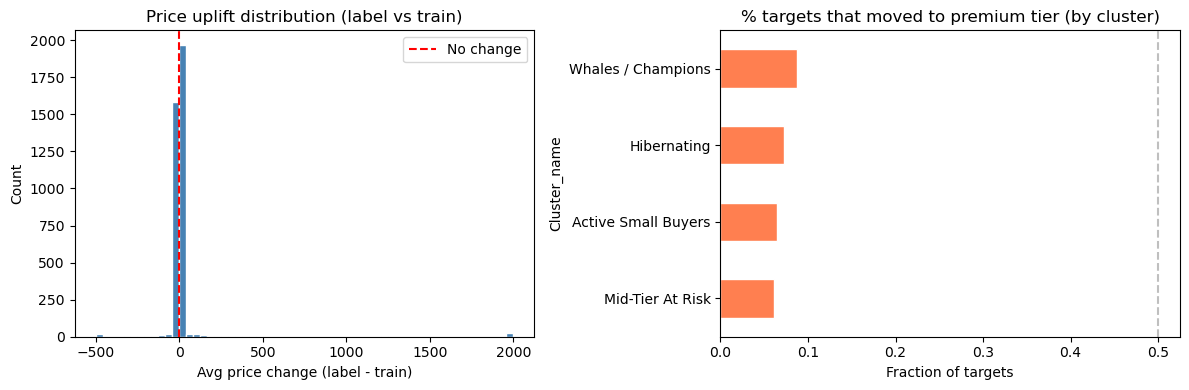

In [12]:
# Distribution of price uplift
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Clip extreme outliers for readability
clipped = price_uplift.clip(-500, 2000)
axes[0].hist(clipped, bins=60, color='steelblue', edgecolor='white')
axes[0].axvline(0, color='red', linestyle='--', label='No change')
axes[0].set_title('Price uplift distribution (label vs train)')
axes[0].set_xlabel('Avg price change (label - train)')
axes[0].set_ylabel('Count')
axes[0].legend()

# % moved to premium by cluster
cluster_val['pct_premium'].sort_values().plot(
    kind='barh', ax=axes[1], color='coral', edgecolor='white'
)
axes[1].set_title('% targets that moved to premium tier (by cluster)')
axes[1].set_xlabel('Fraction of targets')
axes[1].axvline(0.5, color='gray', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.savefig('../visualization/upsell_validation.png', dpi=120, bbox_inches='tight')
plt.show()

## 7. Save Outputs

In [13]:
# Up-sell recommendations
recs_df.to_csv(OUT_DATA / 'upsell_recommendations.csv', index=False)
print(f"Saved upsell_recommendations.csv : {len(recs_df):,} rows")

# Item tiers (used by API to classify new items)
item_tiers.to_csv(OUT_DATA / 'item_tiers.csv', index=False)
print(f"Saved item_tiers.csv             : {len(item_tiers):,} rows")

# Item popularity (used by API to serve recommendations at runtime)
item_popularity.to_csv(OUT_DATA / 'upsell_item_popularity.csv', index=False)
print(f"Saved upsell_item_popularity.csv : {len(item_popularity):,} rows")

# PG medians (used by API to classify customers at inference time)
pg_medians.to_csv(OUT_DATA / 'pg_median_prices.csv', index=False)
print(f"Saved pg_median_prices.csv       : {len(pg_medians):,} rows")

# Summary JSON
summary = {
    'train_end'         : str(TRAIN_END.date()),
    'label_end'         : str(LABEL_END.date()),
    'top_k'             : TOP_K,
    'n_target_pairs'    : int(len(targets)),
    'n_target_customers': int(targets['CustomerID'].nunique()),
    'n_recommendations' : int(len(recs_df)),
    'n_items_tiered'    : int(len(item_tiers)),
    'n_premium_items'   : int((item_tiers['tier'] == 'premium').sum()),
    'validation': {
        'n_with_label_data'  : int(len(has_label)),
        'coverage_pct'       : round(float(coverage), 4),
        'avg_price_uplift'   : round(float(price_uplift.mean()), 4),
        'pct_positive_uplift': round(float((price_uplift > 0).mean()), 4),
        'pct_moved_premium'  : round(float(moved_premium.mean()), 4),
    }
}

with open(OUT_MODEL / 'upsell_meta.json', 'w') as f:
    json.dump(summary, f, indent=2)

print()
print('--- Up-Sell Model Summary ---')
for k, v in summary.items():
    if k == 'validation':
        print('Validation:')
        for vk, vv in v.items():
            print(f'  {vk}: {vv}')
    else:
        print(f'{k}: {v}')
print()
print(f'Output data  → {OUT_DATA}')
print(f'Output model → {OUT_MODEL}')

Saved upsell_recommendations.csv : 27,744 rows
Saved item_tiers.csv             : 38,734 rows
Saved upsell_item_popularity.csv : 4,142 rows
Saved pg_median_prices.csv       : 30 rows

--- Up-Sell Model Summary ---
train_end: 2019-07-01
label_end: 2020-07-01
top_k: 5
n_target_pairs: 6458
n_target_customers: 4993
n_recommendations: 27744
n_items_tiered: 38734
n_premium_items: 19382
Validation:
  n_with_label_data: 3720
  coverage_pct: 0.5988
  avg_price_uplift: 35.6247
  pct_positive_uplift: 0.4425
  pct_moved_premium: 0.0761

Output data  → ../data/processed/upsell
Output model → ../models/upsell
